# המאפייה של דנה — LangGraph

מערכת דטרמיניסטית לטיפול בהזמנות: בדיקת קלט ומלאי, עד שתי חלופות, תמחור והנחות, משלוח ותשובה ללקוח. המחברת כוללת ציור גרף ו־18 הזמנות בדיקה.


## 1. התקנת הספרייה

הריצו את התא הבא ב־Google Colab. `%pip` מתקין את LangGraph בסביבת המחברת. הספרייה תאפשר בהמשך לחבר פעולות לצמתים ולמסלולים. אין צורך במפתח API.

In [ ]:
%pip install -q langgraph


## 2. מחירים ומלאי

מילון (`dict`) מחבר מפתח לערך: כאן שם המוצר הוא המפתח, והמחיר או הכמות הם הערך. השמות באנגלית יתאימו לקלט שהמטלה דורשת.

בבקה מופיעה במחירים עם מלאי אפס: היא מוצר תקין שאזל. קרואסון אינו מופיע, כי הוא כבר לא נמכר. `rugelach` מייצג קופסת רוגלך.

בהמשך כל הזמנה תיבדק באופן עצמאי מול המלאי ההתחלתי. זו הנחת מימוש מפורשת, משום שהסיפור אינו מגדיר ניהול מלאי בין הזמנות.

In [1]:
PRICES = {
    "challah": 18,
    "babka": 45,
    "rugelach": 30,
    "sourdough": 25,
}

INITIAL_STOCK = {
    "challah": 10,
    "babka": 0,
    "rugelach": 3,
    "sourdough": 4,
}


## 3. קריאת ערכים מהמילונים

סוגריים מרובעים מאפשרים לשלוף ערך לפי שם המוצר. התא הבא מציג את מחיר החלה ואת מלאי הבבקה. התוצאה הצפויה היא 18 ו־0.

In [2]:
print("מחיר חלה:", PRICES["challah"])
print("מלאי בבקה:", INITIAL_STOCK["babka"])


מחיר חלה: 18
מלאי בבקה: 0


## 4. כרטיס ההזמנה — State

ה־State הוא מילון שמלווה הזמנה בין הצמתים. כל צומת קורא ממנו מידע ומחזיר עדכונים. `TypedDict` מתאר את שמות השדות ואת סוגי הערכים הצפויים; הוא אינו בודק קלט בזמן ריצה. נבנה צומת נפרד לבדיקת קלט.

`total=False` מאפשר להזמנה להתחיל עם ארבעת שדות הקלט בלבד. השדות האחרים נוצרים במהלך העיבוד.

- `item`: המוצר הנוכחי; עשוי להשתנות לחלופה.
- `original_item`: הבקשה המקורית, לצורך הודעות ודחייה.
- `quantity`, `day`, `city`: הכמות, היום והעיר.
- `alternative_attempts`: מספר החלופות שנבדקו.
- `subtotal`, `discount`, `total`: מחיר המאפים לפני הנחה, סכום ההנחה והסכום הסופי.
- `status`, `delivery`, `message`: תוצאת הטיפול, אופן הקבלה וההודעה.
- `reason`: הסבר פנימי להחלטה.
- `steps`: רשימת התחנות שההזמנה עברה, לפי הסדר.

לשדות הקלט הבלתי מהימנים נשתמש ב־`object`, משום שבדיקת התקינות צריכה לטפל גם בערכים מסוג שגוי. הטיפוס `Literal` מתאר ערכים מותרים בשדות התוצאה.

In [3]:
from typing import Literal, TypedDict


class OrderState(TypedDict, total=False):
    item: object
    quantity: object
    day: object
    city: object
    original_item: object
    alternative_attempts: int
    subtotal: float
    discount: float
    total: float
    status: Literal["accepted", "rejected"]
    delivery: Literal["pickup", "delivery"]
    in_stock: bool
    reason: str
    message: str
    steps: list[str]


## 5. הזמנה בתחילת הדרך

זו הזמנת שתי בבקות ביום חמישי לירושלים. עדיין לא בדקנו מלאי ולא חישבנו מחיר. לכן מופיעים רק ארבעת שדות הקלט. ההערה `: OrderState` מתארת את מבנה המשתנה; היא לא מפעילה את הגרף.

In [4]:
example_order: OrderState = {
    "item": "babka",
    "quantity": 2,
    "day": "Thursday",
    "city": "Jerusalem",
}

print(example_order)


{'item': 'babka', 'quantity': 2, 'day': 'Thursday', 'city': 'Jerusalem'}


## 6. הצומת הראשון — בדיקת תקינות

צומת הוא פונקציית Python שמקבלת את ה־State ומחזירה מילון של שדות לעדכון. LangGraph יחבר בהמשך את העדכונים למצב הקיים.

`state.get` קורא שדה בלי להיכשל אם הוא חסר. מוצר תקין הוא מחרוזת שמופיעה במחירון. כמות תקינה היא מספר שלם חיובי; בדיקה באמצעות `type(...) is int` פוסלת גם ערכי בוליאן כמו `True`.

הצומת מאתחל את שדות העיבוד ואת רשימת השלבים לכל הזמנה. הוא מחזיר `reason` ריק כשאפשר להמשיך, או סיבת שגיאה וסטטוס דחייה אם הקלט אינו תקין. הודעת הלקוח תיווצר בצומת נפרד. הזמנה תקינה עדיין אינה מתקבלת סופית: קודם יש לבדוק מלאי. בבקה עם מלאי אפס עוברת את בדיקת התקינות.

In [5]:
def validate_order(state: OrderState) -> dict:
    item = state.get("item")
    quantity = state.get("quantity")

    updates = {
        "original_item": item,
        "alternative_attempts": 0,
        "subtotal": 0.0,
        "discount": 0.0,
        "total": 0.0,
        "delivery": "pickup",
        "reason": "",
        "message": "",
        "steps": ["validate_order"],
    }

    if not isinstance(item, str) or item not in PRICES:
        updates.update(status="rejected", reason="unknown_product")
    elif type(quantity) is not int or quantity <= 0:
        updates.update(status="rejected", reason="invalid_quantity")

    elif not isinstance(state.get("day"), str) or state["day"].strip().lower() not in {
        "monday", "tuesday", "wednesday", "thursday", "friday", "saturday", "sunday"
    }:
        updates.update(status="rejected", reason="invalid_day")
    elif not isinstance(state.get("city"), str):
        updates.update(status="rejected", reason="invalid_city")

    return updates


## 7. הדגמה ובדיקת הצומת

בשלב הזה עוד אין גרף, ולכן נשלב ידנית את ההזמנה ואת עדכוני הפונקציה בעזרת `{**order, **updates}`. `assert` מוודא שהתוצאה תואמת לציפייה; אם לא, ההרצה נעצרת בשגיאה. הבדיקות אינן בודקות זמינות מלאי, משום שזה תפקידו של הצומת הבא.

In [6]:
validation_examples = [
    ({"item": "babka", "quantity": 2}, ""),
    ({"item": "pizza", "quantity": 2}, "unknown_product"),
    ({"item": "challah", "quantity": 0}, "invalid_quantity"),
    ({"item": "challah", "quantity": -2}, "invalid_quantity"),
    ({"item": "challah", "quantity": 1.5}, "invalid_quantity"),
    ({"item": "challah", "quantity": True}, "invalid_quantity"),
]

for order, expected_reason in validation_examples:
    order = {"day": "Thursday", "city": "Jerusalem", **order}
    checked_order = {**order, **validate_order(order)}
    assert checked_order["reason"] == expected_reason
    if expected_reason:
        assert checked_order["status"] == "rejected"
        assert checked_order["total"] == 0
    print(order, "→", checked_order["reason"] or "valid; continue to stock check")

print("All validation checks passed.")


{'day': 'Thursday', 'city': 'Jerusalem', 'item': 'babka', 'quantity': 2} → valid; continue to stock check
{'day': 'Thursday', 'city': 'Jerusalem', 'item': 'pizza', 'quantity': 2} → unknown_product
{'day': 'Thursday', 'city': 'Jerusalem', 'item': 'challah', 'quantity': 0} → invalid_quantity
{'day': 'Thursday', 'city': 'Jerusalem', 'item': 'challah', 'quantity': -2} → invalid_quantity
{'day': 'Thursday', 'city': 'Jerusalem', 'item': 'challah', 'quantity': 1.5} → invalid_quantity
{'day': 'Thursday', 'city': 'Jerusalem', 'item': 'challah', 'quantity': True} → invalid_quantity
All validation checks passed.


## 8. מלאי וחלופות

נוסיף שדה פנימי `in_stock`. בדיקת המלאי אינה משנה את המוצר. צומת החלופה מתקדם מוצר אחד בשרשרת, מגדיל את המונה ובודק זמינות. הקשתות שנוסיף בהמשך מגבילות לשני ניסיונות.

In [7]:
NEXT_ITEM = {"babka": "rugelach", "rugelach": "sourdough", "sourdough": "challah"}


def check_stock(state: OrderState) -> dict:
    return {
        "in_stock": INITIAL_STOCK[state["item"]] >= state["quantity"],
        "steps": state["steps"] + ["check_stock"],
    }


def next_alternative(state: OrderState) -> dict:
    replacement = NEXT_ITEM[state["item"]]
    return {
        "item": replacement,
        "alternative_attempts": state["alternative_attempts"] + 1,
        "in_stock": INITIAL_STOCK[replacement] >= state["quantity"],
        "steps": state["steps"] + [f"next_alternative:{replacement}"],
    }


## 9. מחיר, הנחה ומשלוח

מחשבים לפי המוצר שנבחר בפועל. `Decimal` מאפשר חישוב כספי עשרוני מדויק. ההנחה היא סכום כסף, ולא אחוז. משלוח מתווסף רק לאחר ההנחה. יום חסר או לא מוכר ועיר שאינה טקסט יידחו בבדיקת התקינות כהנחת קלט נוספת; ימי השבוע מתקבלים באנגלית עם התעלמות מרווחים ואותיות גדולות.

In [8]:
from decimal import Decimal, ROUND_HALF_UP


def money(value):
    return float(value.quantize(Decimal("0.01"), rounding=ROUND_HALF_UP))


def price_goods(state: OrderState) -> dict:
    subtotal = Decimal(PRICES[state["item"]]) * state["quantity"]
    eligible = subtotal > 150 and state["day"].strip().lower() != "friday"
    discount = subtotal * Decimal("0.15") if eligible else Decimal("0")
    return {
        "subtotal": money(subtotal), "discount": money(discount),
        "status": "accepted", "steps": state["steps"] + ["price_goods"],
    }


def fulfill_order(state: OrderState) -> dict:
    city = state["city"].strip().lower()
    delivery = "delivery" if city == "jerusalem" else "pickup"
    fee = Decimal("20") if delivery == "delivery" else Decimal("0")
    total = Decimal(str(state["subtotal"])) - Decimal(str(state["discount"])) + fee
    return {
        "delivery": delivery, "total": money(total),
        "steps": state["steps"] + ["fulfill_order"],
    }


def reject_order(state: OrderState) -> dict:
    return {
        "status": "rejected", "item": state["original_item"],
        "total": 0.0, "delivery": "pickup",
        "reason": state["reason"] or "insufficient_stock",
        "steps": state["steps"] + ["reject_order"],
    }


## 10. הודעות ללקוח

ההודעה מורכבת מתבניות קבועות, ללא מודל AI. היא מסבירה החלפה, הנחה, מעבר לאיסוף או סיבת דחייה.

In [9]:
def respond(state: OrderState) -> dict:
    if state["status"] == "rejected":
        reasons = {
            "unknown_product": "המוצר שביקשת אינו נמכר אצלנו.",
            "invalid_quantity": "יש להזין כמות שהיא מספר שלם וחיובי.",
            "invalid_day": "יש להזין יום תקין בשבוע באנגלית.",
            "invalid_city": "יש להזין עיר כטקסט, או טקסט ריק לאיסוף עצמי.",
            "insufficient_stock": "אין לנו מספיק מהמוצר או מהחלופות המותרות.",
        }
        message = "מצטערים, ההזמנה לא בוצעה. " + reasons[state["reason"]]
    else:
        parts = ["בשמחה! ההזמנה שלך התקבלה."]
        if state["item"] != state["original_item"]:
            parts.append(f'במקום {state["original_item"]}, הכנו {state["quantity"]} יחידות של {state["item"]}.')
        if state["discount"]:
            parts.append(f'ההזמנה קיבלה הנחה של {state["discount"]:.2f} ש״ח.')
        if state["delivery"] == "delivery":
            parts.append('משלוח לירושלים בעלות 20 ש״ח כלול במחיר.')
        elif state["city"].strip():
            parts.append("אנחנו לא שולחים מחוץ לירושלים, ולכן ההזמנה הועברה לאיסוף עצמי בחינם.")
        else:
            parts.append("ההזמנה מיועדת לאיסוף עצמי בחינם.")
        parts.append(f'סה״כ לתשלום: {state["total"]:.2f} ש״ח. תודה מדנה והצוות!')
        message = " ".join(parts)
    return {"message": message, "steps": state["steps"] + ["respond"]}


## 11. חיבור הגרף

`add_node` מוסיף תחנה. `add_edge` מחבר מסלול קבוע. `add_conditional_edges` בוחר מסלול לפי תוצאת פונקציה. `compile` הופך את התכנון לגרף שאפשר להריץ. אחרי מלאי זמין ממשיכים לתמחור; כשחסר, בודקים אם נשארו ניסיונות ואם קיימת חלופה נוספת.

In [10]:
from langgraph.graph import StateGraph, START, END


def route_validation(state):
    return "reject_order" if state["reason"] else "check_stock"


def route_stock(state):
    if state["in_stock"]:
        return "price_goods"
    if state["alternative_attempts"] < 2 and state["item"] in NEXT_ITEM:
        return "next_alternative"
    return "reject_order"


builder = StateGraph(OrderState)
for name, function in {
    "validate_order": validate_order,
    "check_stock": check_stock,
    "next_alternative": next_alternative,
    "price_goods": price_goods,
    "fulfill_order": fulfill_order,
    "reject_order": reject_order,
    "respond": respond,
}.items():
    builder.add_node(name, function)

builder.add_edge(START, "validate_order")
builder.add_conditional_edges("validate_order", route_validation,
                              ["reject_order", "check_stock"])
for name in ["check_stock", "next_alternative"]:
    builder.add_conditional_edges(name, route_stock,
                                  ["price_goods", "next_alternative", "reject_order"])
builder.add_edge("price_goods", "fulfill_order")
builder.add_edge("fulfill_order", "respond")
builder.add_edge("reject_order", "respond")
builder.add_edge("respond", END)
graph = builder.compile()


## 12. ציור הגרף

התא משתמש ב־`draw_mermaid_png()` כנדרש. ברירת המחדל פונה לשירות ציור חיצוני; לכן נדרש חיבור רשת כדי להציג את התמונה. עיבוד ההזמנות עצמו אינו דורש רשת.

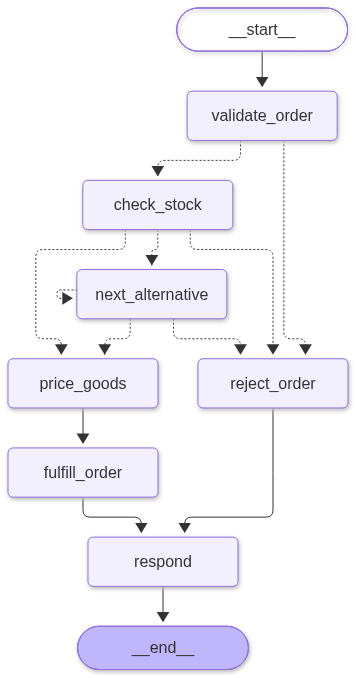

In [10]:
from IPython.display import Image, display

display(Image(graph.get_graph().draw_mermaid_png()))


## 13. הרצת הזמנה

`invoke` מפעיל את מסלול ההזמנה מתחילתו ועד סופו. בדוגמה מתקבלים שני רוגלך במחיר 60 ועוד 20 למשלוח: 80 ש״ח.

In [11]:
result = graph.invoke({"item": "babka", "quantity": 2,
                       "day": "Thursday", "city": "Jerusalem"})
for key in ["status", "item", "delivery", "total", "message", "steps"]:
    print(f"{key}: {result[key]}")


status: accepted
item: rugelach
delivery: delivery
total: 80.0
message: בשמחה! ההזמנה שלך התקבלה. במקום babka, הכנו 2 יחידות של rugelach. משלוח לירושלים בעלות 20 ש״ח כלול במחיר. סה״כ לתשלום: 80.00 ש״ח. תודה מדנה והצוות!
steps: ['validate_order', 'check_stock', 'next_alternative:rugelach', 'price_goods', 'fulfill_order', 'respond']


## 14. בדיקות מסלולים וגבולות

הבדיקות מכסות אישור ישיר, החלפה ראשונה ושנייה, ביטול, הנחה וסף ההנחה, משלוחים וקלט שגוי. כל הרצה עצמאית מול המלאי ההתחלתי. בנוסף נבדוק שתיעוד השלבים תואם למסלול ושהמלאי אינו משתנה. אלו בדיקות התוכנה שלנו, ולא שאלות לימודיות למשתמשת.

In [12]:
def order(item, quantity, day="Thursday", city=""):
    return dict(item=item, quantity=quantity, day=day, city=city)


# name, input, expected status, product, total, fulfillment, alternatives
cases = [
    ("direct pickup", order("challah", 2), "accepted", "challah", 36.0, "pickup", 0),
    ("first alternative", order("babka", 2, city="Jerusalem"), "accepted", "rugelach", 80.0, "delivery", 1),
    ("second alternative", order("babka", 4), "accepted", "sourdough", 100.0, "pickup", 2),
    ("two failures", order("babka", 5), "rejected", "babka", 0, "pickup", 2),
    ("chain exhausted", order("challah", 11), "rejected", "challah", 0, "pickup", 0),
    ("chain ends after retry", order("sourdough", 11), "rejected", "sourdough", 0, "pickup", 1),
    ("unknown item", order("pizza", 1), "rejected", "pizza", 0, "pickup", 0),
    ("discontinued item", order("croissant", 1), "rejected", "croissant", 0, "pickup", 0),
    ("zero", order("challah", 0), "rejected", "challah", 0, "pickup", 0),
    ("negative", order("babka", -2), "rejected", "babka", 0, "pickup", 0),
    ("fraction", order("challah", 1.5), "rejected", "challah", 0, "pickup", 0),
    ("boolean", order("challah", True), "rejected", "challah", 0, "pickup", 0),
    ("discount plus delivery", order("challah", 10, city="Jerusalem"), "accepted", "challah", 173.0, "delivery", 0),
    ("Friday no discount", order("challah", 10, day="Friday"), "accepted", "challah", 180.0, "pickup", 0),
    ("outside city", order("challah", 2, city="Tel Aviv"), "accepted", "challah", 36.0, "pickup", 0),
    ("replacement discount", order("rugelach", 10), "accepted", "challah", 153.0, "pickup", 2),
    ("invalid day", order("challah", 1, day="Funday"), "rejected", "challah", 0, "pickup", 0),
    ("invalid city", order("challah", 1, city=None), "rejected", "challah", 0, "pickup", 0),
]
required_keys = {"status", "item", "delivery", "total", "message", "steps"}
stock_before = INITIAL_STOCK.copy()
results = {}
for name, request, status, item, total, delivery, attempts in cases:
    actual = graph.invoke(request)
    assert required_keys <= actual.keys(), name
    assert (actual["status"], actual["item"], actual["total"], actual["delivery"],
            actual["alternative_attempts"]) == (status, item, total, delivery, attempts), name
    assert actual["steps"][0] == "validate_order" and actual["steps"][-1] == "respond", name
    assert sum(s.startswith("next_alternative:") for s in actual["steps"]) == attempts, name
    assert isinstance(actual["message"], str) and actual["message"], name
    if status == "accepted":
        assert actual["steps"][-3:] == ["price_goods", "fulfill_order", "respond"], name
    else:
        assert actual["steps"][-2:] == ["reject_order", "respond"], name
    results[name] = actual
    print(f"PASS: {name} | {status} | {total:.2f}")

# Exactly 150 cannot be reached with the initial stock. Test the pricing boundary
# directly, with 5 rugelach, rather than changing the real inventory.
assert price_goods({"item": "rugelach", "quantity": 5, "day": "Thursday", "steps": []})["discount"] == 0
assert results["discount plus delivery"]["discount"] == 27
assert results["Friday no discount"]["discount"] == 0
assert "איסוף עצמי" in results["outside city"]["message"]
assert "babka" in results["first alternative"]["message"]
assert results["second alternative"]["steps"] == [
    "validate_order", "check_stock", "next_alternative:rugelach",
    "next_alternative:sourdough", "price_goods", "fulfill_order", "respond"
]
assert INITIAL_STOCK == stock_before
print(f"All {len(cases)} graph cases and pricing-boundary checks passed.")


PASS: direct pickup | accepted | 36.00
PASS: first alternative | accepted | 80.00
PASS: second alternative | accepted | 100.00
PASS: two failures | rejected | 0.00
PASS: chain exhausted | rejected | 0.00
PASS: chain ends after retry | rejected | 0.00
PASS: unknown item | rejected | 0.00
PASS: discontinued item | rejected | 0.00
PASS: zero | rejected | 0.00
PASS: negative | rejected | 0.00
PASS: fraction | rejected | 0.00
PASS: boolean | rejected | 0.00
PASS: discount plus delivery | accepted | 173.00
PASS: Friday no discount | accepted | 180.00
PASS: outside city | accepted | 36.00
PASS: replacement discount | accepted | 153.00
PASS: invalid day | rejected | 0.00
PASS: invalid city | rejected | 0.00
All 18 graph cases and pricing-boundary checks passed.


## הגשה והנחות

המחברת והקובץ `prompt.md` מיועדים להעלאה למאגר GitHub ציבורי. יש לפתוח את המחברת ב־Colab, להריץ הכול כולל ציור הגרף, לשמור את הפלט ולשתף קישור שהמרצה יכול לפתוח.

הנחות מפורשות: כל הזמנה עצמאית מול מלאי התחלתי קבוע; בדחייה נשמר המוצר המקורי, המחיר אפס ו־pickup הוא ערך מבני בלבד; יום לא תקין או עיר שאינה טקסט נדחים; שמות המוצרים באנגלית תואמים בדיוק למחירון. חלופה נבחרת אוטומטית לפי הסיפור, ללא שלב אישור נוסף מהלקוח. המחברת אינה משתמשת ב־LLM.